In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("customer_spending_dataset.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully!
Shape: (200, 9)


,Customer_ID,Age,Annual_Income,Purchase_Frequency,Avg_Order_Value,Membership_Years,Website_Visits,Monthly_Spending,Spending_Category
0,1,56,1382310,7,3482,8,10,24374,Medium
1,2,46,259751,15,3794,1,5,56910,High
2,3,32,961774,9,1656,10,27,14904,Medium
3,4,60,611079,12,1232,4,10,14784,Medium
4,5,25,518452,5,4830,1,1,24150,Medium


In [2]:
print("Missing values:\n")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:\n")
print(df.dtypes)

Missing values:

Customer_ID           0
Age                   0
Annual_Income         0
Purchase_Frequency    0
Avg_Order_Value       0
Membership_Years      0
Website_Visits        0
Monthly_Spending      0
Spending_Category     0
dtype: int64

Duplicate rows: 0

Data types:

Customer_ID            int64
Age                    int64
Annual_Income          int64
Purchase_Frequency     int64
Avg_Order_Value        int64
Membership_Years       int64
Website_Visits         int64
Monthly_Spending       int64
Spending_Category     object
dtype: object


In [3]:
df_clean = df.copy()

df_clean = df_clean.drop_duplicates()

numeric_cols = df_clean.select_dtypes(include="number").columns
df_clean[numeric_cols] = df_clean[numeric_cols].fillna(
    df_clean[numeric_cols].median()
)

categorical_cols = df_clean.select_dtypes(include="object").columns
for col in categorical_cols:
    if df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].fillna(
            df_clean[col].mode()[0]
        )

print("Cleaning completed!")
print("Cleaned shape:", df_clean.shape)
print("Remaining missing values:", df_clean.isnull().sum().sum())

Cleaning completed!
Cleaned shape: (200, 9)
Remaining missing values: 0


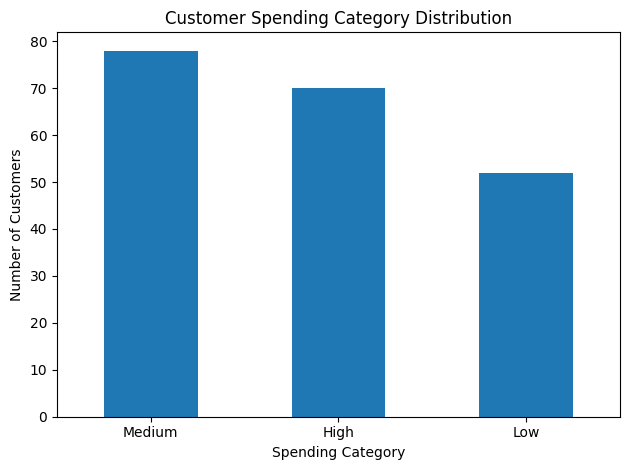

In [4]:
df_clean["Spending_Category"].value_counts().plot(
    kind="bar", rot=0
)
plt.title("Customer Spending Category Distribution")
plt.xlabel("Spending Category")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

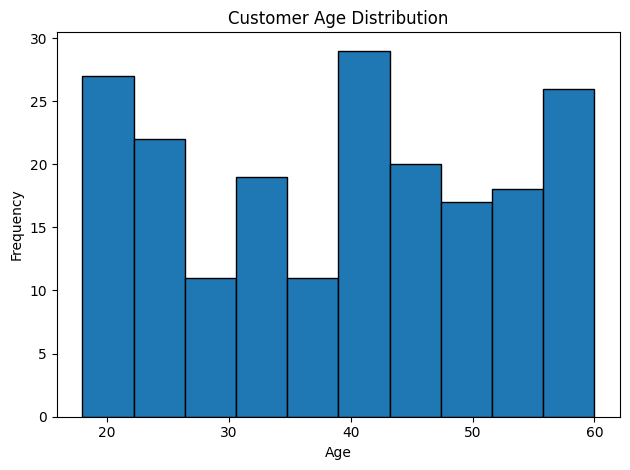

In [5]:
plt.hist(df_clean["Age"], bins=10, edgecolor="black")
plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

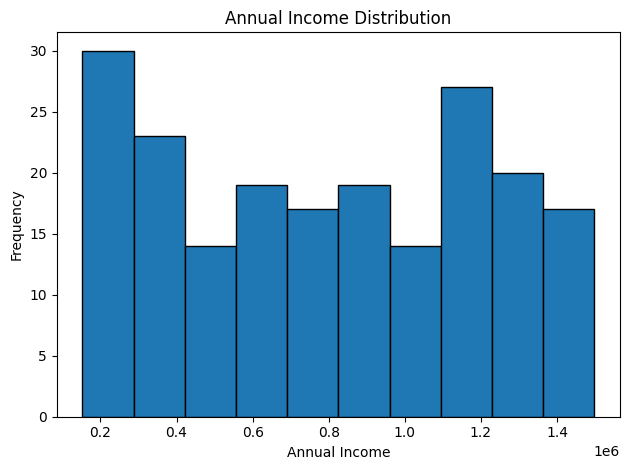

In [6]:
plt.hist(df_clean["Annual_Income"], bins=10, edgecolor="black")
plt.title("Annual Income Distribution")
plt.xlabel("Annual Income")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

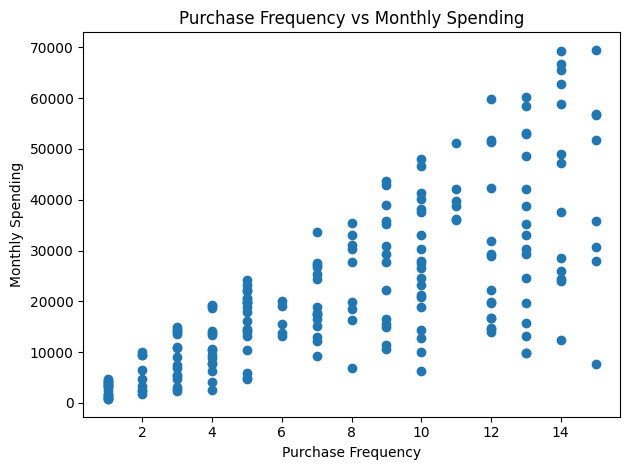

In [7]:
plt.scatter(
    df_clean["Purchase_Frequency"],
    df_clean["Monthly_Spending"]
)
plt.title("Purchase Frequency vs Monthly Spending")
plt.xlabel("Purchase Frequency")
plt.ylabel("Monthly Spending")
plt.tight_layout()
plt.show()

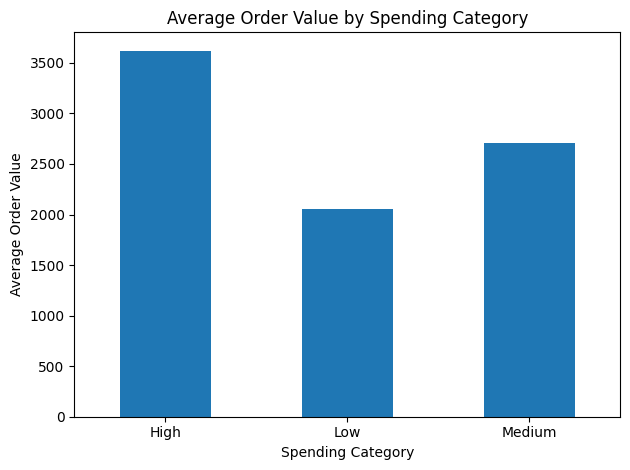

In [8]:
df_clean.groupby("Spending_Category")["Avg_Order_Value"].mean().plot(
    kind="bar", rot=0
)
plt.title("Average Order Value by Spending Category")
plt.xlabel("Spending Category")
plt.ylabel("Average Order Value")
plt.tight_layout()
plt.show()

In [9]:
print("CLEANED DATASET SUMMARY")
print("-----------------------")
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])
print("Missing values:", df_clean.isnull().sum().sum())
print("Duplicates:", df_clean.duplicated().sum())

df_clean.to_csv("customer_spending_cleaned.csv", index=False)
print("\nCleaned dataset saved successfully!")

CLEANED DATASET SUMMARY
-----------------------
Rows: 200
Columns: 9
Missing values: 0
Duplicates: 0

Cleaned dataset saved successfully!
